<div class="alert alert-danger" role="alert">
  Note: <br>
    1. Only modify the area marked by "YOUR CODE STARTS HERE" and "YOUR CODE ENDS HERE" markers<br>
    2. If you are working locally, the data files should be in the same directory as your Assignment3.ipynb Notebook.<br>
</div>

Elias:Sorry Hassan for deleting all comments in Ass2 I thought it was more neat, clean, and easier for you to work on. Below they are intact, I put my comments in new cells starting 'Elias' and ending 'End'. End.

# Assignment 3: Image classification

## Instructions

In this assignment, you will be working on the COVID-19 lung X-Ray dataset. It consists of X-ray images that are labeled as either "Normal" or "Covid", with the latter indicating an X-ray of a COVID-19 patient.

To predict if a person has COVID or not, you will train the following five different classification models, finetune their hyperparameters, and finally select the best model and test it on the test data.

1.   Decision Tree
2.   Gradient Boosting
3.   Random Forest
4.   Support Vector Machines
5.   Neural Netwroks

The dataset can be found here: [Covid 19 X-Ray Dataset](https://drive.google.com/drive/folders/1Nwa6L58NwF23PvImpDrp-W8oTOheu_b3?usp=sharing). The data is already split into training, validation, and test.

To help you with this assignment, you are provided some instructions to follow, we will be checking those criteria when evaluating your submissions.

Elias:In this Ass3, I became conscious that data type will guide me through my projects, so first thing I should look into is my data what type is it, how is it organized.. to choose implementation course, which model algorithm to use, what tools and functions are afterwards necessary. Of course what I want from my data also counts. I should know where I am heading too, to know how to use and handle my data. End

## Part 1: Data Exploration
First, we need to load and explore the dataset. Make sure to place the downloaded dataset in the same directory.

# New Section

In [1]:
# define the path for training, testing and validation datasets
from google.colab import drive
drive.mount('/content/drive')
train_dir = "/content/drive/MyDrive/Colab Notebooks/Assignment 3/Dataset/Training"
val_dir = "/content/drive/MyDrive/Colab Notebooks/Assignment 3/Dataset/Validation"
test_dir = "/content/drive/MyDrive/Colab Notebooks/Assignment 3/Dataset/Testing"

Mounted at /content/drive


Elias:I mounted Drive in this cell and chaged the path to reach all folders. End.

In [2]:
# install necessary libraries
!pip install -U "scikit-learn>=1.4,<1.6"
!pip install scikeras
!pip install keras

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.9/12.9 MB 59.7 MB/s eta 0:00:00
  Attempting uninstall: scikit-learn
    Found existing installation: scikit-learn 1.6.1
    Uninstalling scikit-learn-1.6.1:
      Successfully uninstalled scikit-learn-1.6.1
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
umap-learn 0.5.9.post2 requires scikit-learn>=1.6, but you have scikit-learn 1.5.2 which is incompatible.


Elias: In the above cell, our project needed Keras which is found in a certain version of scikit-learn(not all), so that version was targeted for Keras retrieval. End.

In [3]:
# Standard Libraries
import os
import numpy as np
import matplotlib.pyplot as plt
import cv2

# Scikit-learn Models & Utilities
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.model_selection import GridSearchCV, learning_curve, StratifiedKFold
from sklearn.metrics import accuracy_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer

# Keras / TensorFlow for Neural Networks
from scikeras.wrappers import KerasClassifier, KerasRegressor
from keras.models import Sequential
from keras.layers import Input, Flatten
from tensorflow.keras.layers import Dense
from tensorflow.keras import backend as K

In [4]:
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'


Elias: This is to regulate the work of TensorFlow and limit it to the necessary we need.End.

Since we are dealing with folders and subfolders, it's crucial to use the os library so that we will be able to use the

```python
os.path.join(folder, 'Dataset')
```

where the destination will be either "COVID" or "Normal".



In [5]:
# Function to count samples in each folder
def count_samples(folder):
    covid_path = os.path.join(folder, 'COVID')
    normal_path = os.path.join(folder, 'Normal')
    num_covid = len(os.listdir(covid_path))
    num_normal = len(os.listdir(normal_path))
    return num_covid, num_normal

# Count samples in each folder
train_covid, train_normal = count_samples(train_dir)
test_covid, test_normal = count_samples(test_dir)
val_covid, val_normal = count_samples(val_dir)

# Output the counts
print("Number of samples in each folder:")
print("Training - COVID:", train_covid)
print("Training - Normal:", train_normal)
print("Validation - COVID:", val_covid)
print("Validation - Normal:", val_normal)
print("Testing - COVID:", test_covid)
print("Testing - Normal:", test_normal)

Number of samples in each folder:
Training - COVID: 200
Training - Normal: 200
Validation - COVID: 50
Validation - Normal: 50
Testing - COVID: 25
Testing - Normal: 25


Elias: Our data is already organized in 3 folders (training, validation, testing), and 6 subfolders (two for each folder: covid and normal). In the above cell, we are directing our work to ensure the training will be done on the training data (retrieval from their related folder), validation on Val folder etc to ensure no data leakage will happen.End.

Your next step is to visualize some of the data that you have. When we were dealing with a dataframe, it was easier for us to visualize some samples since the dataframe has a head and many other functions to get the job done.

In our case, we are dealing with images. The simplest option is to check the folder from your drive but we want to see it in the code here.

To do that, we will use the cv2 library and use the method

``` python
cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
```
so that we can read an image that is in grayscale.


In addition, the image should be in a viewable format, so we need to plot then show the image using the matplotlib library.


Visualizing 2 COVID images from Training folder:


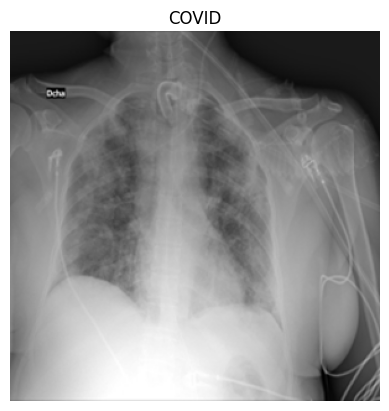

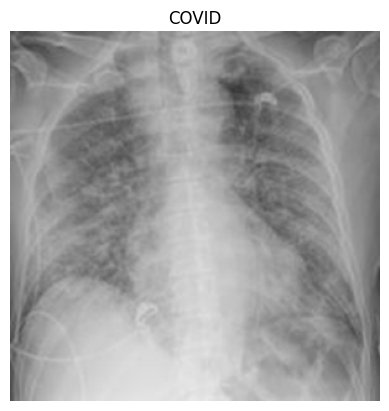


Visualizing 2 Normal images from Training folder:


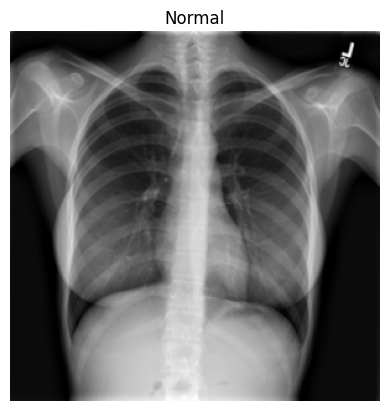

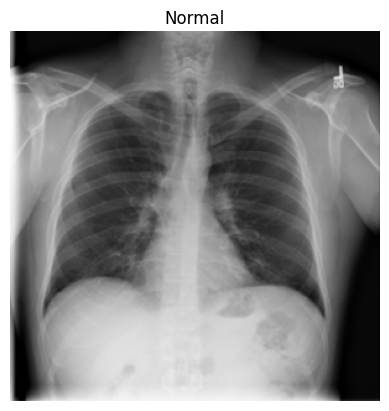


Visualizing 2 COVID images from Testing folder:


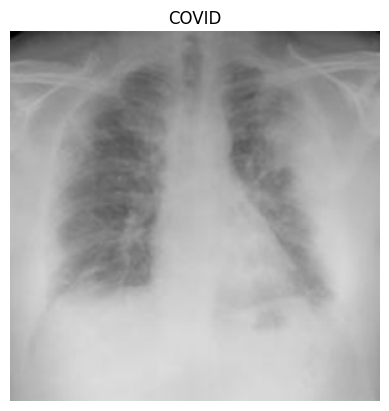

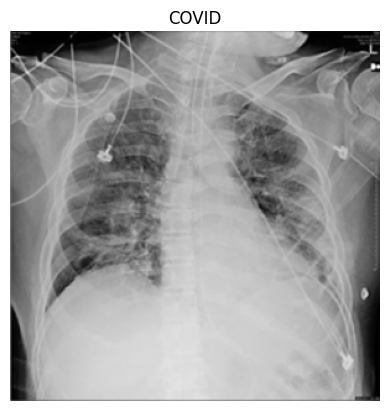


Visualizing 2 Normal images from Testing folder:


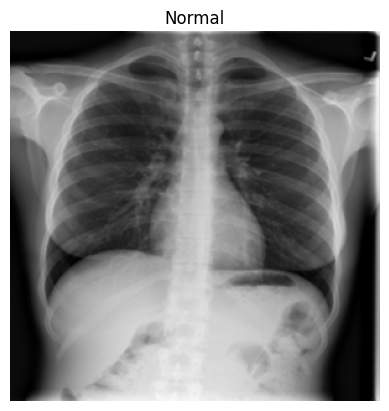

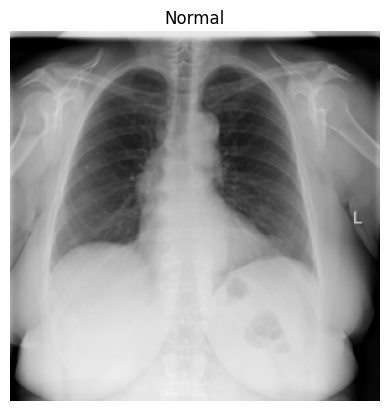


Visualizing 2 COVID images from Validation folder:


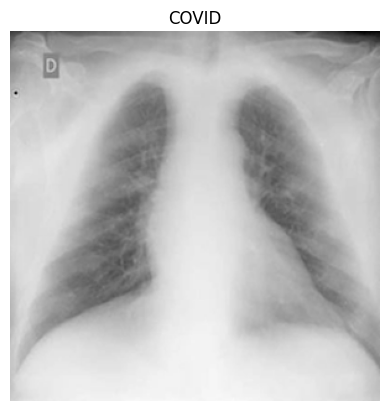

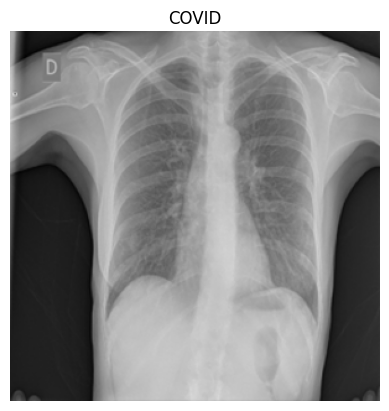


Visualizing 2 Normal images from Validation folder:


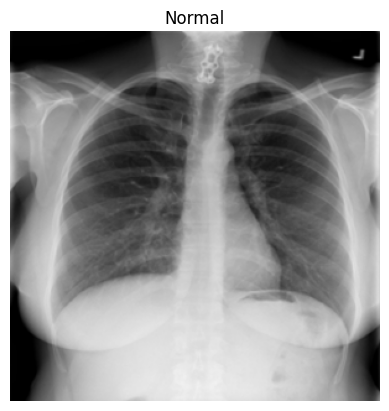

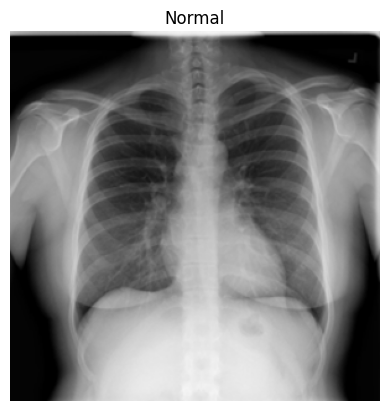

In [6]:
# Function to visualize images from each folder
def visualize_images(folder, label, num_samples=2):
    covid_path = os.path.join(folder, 'COVID')
    normal_path = os.path.join(folder, 'Normal')

    # Visualize COVID images
    covid_images = os.listdir(covid_path)[:num_samples]
    print(f"\nVisualizing {num_samples} COVID images from {label} folder:")
    for img_name in covid_images:
        img_path = os.path.join(covid_path, img_name)
        img = cv2.imread(img_path)
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        plt.imshow(img)
        plt.title("COVID")
        plt.axis('off')
        plt.show()

    # Visualize Normal images
    normal_images = os.listdir(normal_path)[:num_samples]
    print(f"\nVisualizing {num_samples} Normal images from {label} folder:")
    for img_name in normal_images:
        img_path = os.path.join(normal_path, img_name)
        img = cv2.imread(img_path)
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        plt.imshow(img)
        plt.title("Normal")
        plt.axis('off')
        plt.show()

# Visualize images from each folder
visualize_images(train_dir, "Training")
visualize_images(test_dir, "Testing")
visualize_images(val_dir, "Validation")

Elias: Data visualized, labeled (or titled) by folder and subfolder(covid or normal), two of each, so 12 images visible. End

## Part 2: Data Preparation

We need to present our folders and images in a suitable format for the different models.

To do that, we will be using the method

```python
load_images_from_folder()
```
that will take as parameters the folder path and the label, and return 2 arrays, one for the features (which are the images) and one for the labels.

To build this method, we need at first to initiate 2 empty arrays to hold the new values that we will be working with and we need to make a dictionnary to map the labels COVID and Normal to numeric values (0 and 1).

Next, we need to loop over the images inside each folder and do the following:

1.   Read the image
2.   Convert each image to grayscale
3.   Normalize the pixels values between 0 and 1
4.   Flatten the image
5.   Append the image and its label to the correspondng arrays


In [7]:
def load_images_from_folder(folder_path, label, target_size=(100, 100)):
    images = []
    labels = []
    label_dict = {'COVID': 0, 'Normal': 1}  # Define a dictionary to map labels to numeric values
    label_code = label_dict[label]

    label_path = os.path.join(folder_path, label)
    for img_name in os.listdir(label_path):
        img_path = os.path.join(label_path, img_name)
        # Load the image
        img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)  # Read the image in grayscale
        # Resize the image
        img_resized = cv2.resize(img, target_size)  # Resize the image to the specified target size
        # Preprocess the resized image
        img_resized = img_resized.astype('float32') / 255.0  # Normalize pixel values to [0, 1]
        # Flatten the resized image
        img_flat = img_resized.flatten()
        # Append the flattened image and corresponding label
        images.append(img_flat)
        labels.append(label_code)
    return np.array(images), np.array(labels)


Elias: Vectorization, or rather pixelization. Images(our data), in this cell, are first reduced/minimized in size then numerized - turned to points. Crucial step, the models can now do their jobs.End.

Next, call this method for all the folders you have to prepare your data for training.

In [8]:
# Load images from the training folder for both COVID and Normal labels
train_covid_images, train_covid_labels = load_images_from_folder(train_dir, 'COVID')
train_normal_images, train_normal_labels = load_images_from_folder(train_dir, 'Normal')

# Load images from the testing folder for both COVID and Normal labels
test_covid_images, test_covid_labels = load_images_from_folder(test_dir, 'COVID')
test_normal_images, test_normal_labels = load_images_from_folder(test_dir, 'Normal')

# Load images from the validation folder for both COVID and Normal labels
val_covid_images, val_covid_labels = load_images_from_folder(val_dir, 'COVID')
val_normal_images, val_normal_labels = load_images_from_folder(val_dir, 'Normal')

Elias: Loading the newly numerical data into new created sub-folders: the labels. End.

In [9]:
train_covid_images.shape

(200, 10000)

In [10]:
# Combine COVID and Normal images and labels for training, validation and test
train_images = np.concatenate((train_covid_images, train_normal_images), axis=0)
train_labels = np.concatenate((train_covid_labels, train_normal_labels), axis=0)

val_images = np.concatenate((val_covid_images, val_normal_images), axis=0)
val_labels = np.concatenate((val_covid_labels, val_normal_labels), axis=0)

test_images = np.concatenate((test_covid_images, test_normal_images), axis=0)
test_labels = np.concatenate((test_covid_labels, test_normal_labels), axis=0)

Elias: Concatenating both sub categories data(normal and covid), into each of the two functions (train_images and train_labels) of the three data types (training, validation, testing).
So now the result of the training done on training_images will fill up the train_labels. Hassan, this phase was difficult for me to conceive, I am not sure I got it correctly. End.


## Part 3: Models

In [11]:
results = [] # Array used to store tuples of (model, accuracy_score)

Upon calling the function with the corresponding parameters, the most important process is the call to `learning_curve`. This function first splits the dataset according to cross-validation folds and, for each split and training subset size, creates a fresh instance of the model and trains it. This ensures that the evaluation is always performed on data the model has never seen before, providing an unbiased measure of its generalization.
After collecting the training and validation accuracies across folds and subset sizes, the function computes their mean and standard deviation to plot the learning curve. This plot helps us analyze model performance and diagnose bias or variance issues.

In [12]:
def plot_learning_curves(model, x_train, y_train):
    if isinstance(model, SVC) or isinstance(model, GradientBoostingClassifier):
        # Safe size for SVM and GB to prevent long runtime and memory issues
        train_sizes = np.linspace(0.6, 1.0, 10)
    else:
        # Default
        train_sizes = np.linspace(0.1, 1.0, 10)

    # Create a stratified 3-fold cross-validation splitter (keeps class balance)
    cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

    # Learning_curve internally clones the model for each fold & train size
    # Ensuring each evaluation is on a fresh, unfitted instance
    train_sizes, train_scores, val_scores = learning_curve(
        model, x_train, y_train,
        cv=cv, scoring='accuracy',
        train_sizes=train_sizes, n_jobs=-1
    )

    train_scores_mean = np.mean(train_scores, axis=1)
    train_scores_std = np.std(train_scores, axis=1)
    val_scores_mean = np.mean(val_scores, axis=1)
    val_scores_std = np.std(val_scores, axis=1)

    plt.figure(figsize=(10, 6))
    plt.title("Learning Curves")
    plt.xlabel("Training Examples")
    plt.ylabel("Score")
    plt.grid()

    plt.fill_between(train_sizes, train_scores_mean - train_scores_std, train_scores_mean + train_scores_std, alpha=0.1, color="r")
    plt.fill_between(train_sizes, val_scores_mean - val_scores_std, val_scores_mean + val_scores_std, alpha=0.1, color="g")

    plt.plot(train_sizes, train_scores_mean, 'o-', color="r", label="Training score")
    plt.plot(train_sizes, val_scores_mean, 'o-', color="g", label="Cross-validation score")

    plt.legend(loc="best")
    plt.show()

Elias: adjusting criterias for all our curves to come: titles, x and y axis names, colors, putting limitations for SVM and Gb and not for other models; among other criterias. End


### Decision Tree

Train a Decision Tree model using the default hyperparameters and evaluate its performance on the validation set

In [ ]:
##### YOUR CODE STARTS HERE #####
# for more info about the model
# refer to https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeClassifier.html

# Initialize and train the decision tree classifier model
dt_model = DecisionTreeClassifier()

# Train the model
dt_model.fit(train_images, train_labels)

# Predict labels for the validation set
val_pred = dt_model.predict(val_images)

# Report the validation accuracy of the trained model
val_accuracy = accuracy_score(val_labels, val_pred)

##### YOUR CODE ENDS HERE #####
print(f"Validation accuracy: {val_accuracy:.4f}")

Validation accuracy: 0.8700


Plot the learning curve of the trained model to examine bias and variance

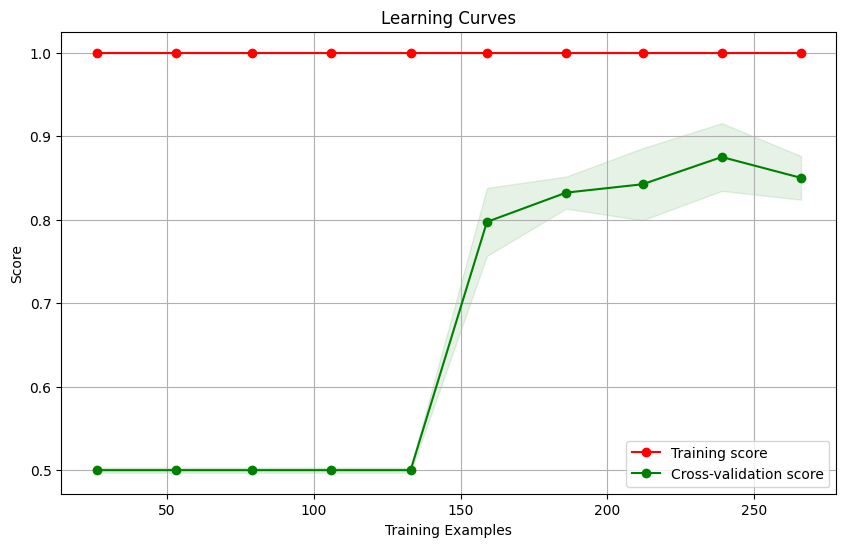

In [ ]:
##### YOUR CODE STARTS HERE #####

# Pass the appropriate parameters to the previously defined function plot_learning_curves()
plot_learning_curves(dt_model, train_images, train_labels)

##### YOUR CODE ENDS HERE #####

Does your model suffer from overfitting, underfitting, neither and why? Elaborate in depth and provide insight based on the bias and variance.

Answer: Elias:As the graph reveals a wide gap between the two curves, the model suffers from high variance - overfitting. The model learnt too well on training phase. End.

#### Comments

You call overfitting and point to a wide gap between train and validation. That matches the curve pattern for a tree with high model size. To strengthen the evidence, anchor it in the right edge: train stays very high while validation lags and the gap doesn't close.

#### Hyperparameter tuning

Use the **GridSearchCV** module of the **sklearn** library to tune the hyperparameters of your `Decision Tree` model on the TRAINING set. You should try to tune as many hyperparameters as you can, such as split `criterion`, `max_depth`, etc. Your tuning should be guided by the observations you made from the learning curve of the untuned model.
Please note that when searching through many parameters, this might take time since it's going through every possible combination.

In [ ]:
##### YOUR CODE STARTS HERE #####
# for more info about gridsearchcv
# refer to https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html

# Define your parameters
param_grid = {
    'max_depth': [3, 5, 10, None],                 # Maximum depth of the tree; None = expand until all leaves are pure
    'min_samples_split': [2, 5, 10],         # Minimum samples required to split an internal node
    'min_samples_leaf': [1, 2, 4],          # Minimum samples required at a leaf node
    'criterion': ['gini', 'entropy'],                  # Function to measure the quality of a split
    'splitter': ['best', 'random'],                 # Strategy to choose the split at each node
    'max_features': [None, 'sqrt', 'log2']         # Number of features to consider when looking for the best split
}

# Initialize the grid search
# Remember to specify cross-validation (cv), scoring metric, and use n_jobs for faster search
grid_search = GridSearchCV(dt_model, param_grid, cv=3, scoring='accuracy', n_jobs=-1)

# Fit the model
grid_search.fit(train_images, train_labels)


##### YOUR CODE ENDS HERE #####

print("Best parameters:", grid_search.best_params_)
print("Best cross-validation score:", grid_search.best_score_)

##### YOUR CODE STARTS HERE #####

# Evaluate the best model on the validation set
# Get the best model
best_model = grid_search.best_estimator_

# Predict labels for the validation set
val_pred = best_model.predict(val_images)

# Report the validation accuracy of the trained model
val_accuracy = accuracy_score(val_labels, val_pred)

##### YOUR CODE ENDS HERE #####

print(f"Validation accuracy with best model: {val_accuracy:.4f}")
results.append((best_model, val_accuracy))

Best parameters: {'criterion': 'entropy', 'max_depth': 5, 'max_features': None, 'min_samples_leaf': 1, 'min_samples_split': 5, 'splitter': 'random'}
Best cross-validation score: 0.9075113156024389
Validation accuracy with best model: 0.8900


Elias: High CV score, it increased a bit the validation score from the initial one by finding a better data set to validate the training data on it.End.

### Gradient Boosting

Train a Gradient Boosting Classifier using the default hyperparameters and evaluate its performance on the validation set

In [ ]:
##### YOUR CODE STARTS HERE #####
# for more info about the model
# refer to https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.GradientBoostingClassifier.html

# Initialize and train the gradient boosting model
gb_model = GradientBoostingClassifier()

# Train the model
gb_model.fit(train_images, train_labels)

# predict labels for the validation set
val_pred = gb_model.predict(val_images)

# report the validation accuracy of the trained model
val_accuracy = accuracy_score(val_labels, val_pred)

##### YOUR CODE ENDS HERE #####
print(f"Validation Accuracy: {val_accuracy:.4f}")

Validation Accuracy: 0.9400


Elias: High score good result. End

Plot the learning curve of the trained model to examine bias and variance

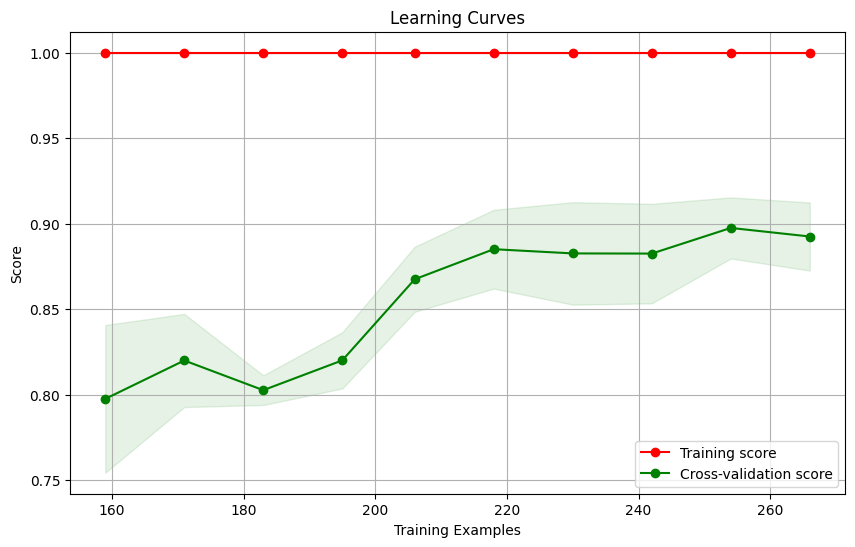

In [ ]:
##### YOUR CODE STARTS HERE #####

# Pass the appropriate parameters to the previously defined function plot_learning_curves()
plot_learning_curves(gb_model, train_images, train_labels)

##### YOUR CODE ENDS HERE #####

Does your model suffer from overfitting, underfitting, neither and why? Elaborate in depth and provide insight based on the bias and variance.

Answer: Elias:Again, the wide gap is the indicator of high variance and overfitting in Gb.

This Gb curve took me long time to generate, and I couldn't minimize that duration.End.


#### Comments

You flag high variance (overfitting) based on a persistent gap while validation improves. That's consistent with boosting's tendency to fit fold quirks. The strongest evidence is the steady train–validation gap as data grows.

#### Hyperparameter tuning

Use the **GridSearchCV** module of the **sklearn** library to tune the hyperparameters of your `Gradient Boosting` model on the TRAINING set. You should try to tune as many hyperparameters as you can, such as the `n_estimators`, `learning_rate`, `max_depth`, and others. Your tuning should be guided by the observations you made from the learning curve of the untuned model.
Please note that when searching through many parameters, this might take time since it's going through every possible combination.

In [ ]:
##### YOUR CODE STARTS HERE #####

# Define your parameters
param_grid = {
    'n_estimators': [100, 200],           # Number of trees in the ensemble (more trees -> better fit but slower)
    'learning_rate': [0.05, 0.2],          # Step size shrinkage to prevent overfitting (lower = slower learning)
    'max_depth': [3, 5],              # Maximum depth of individual trees (controls model complexity)
}


# Initialize the grid search
grid_search = GridSearchCV(gb_model, param_grid, cv=3, scoring='accuracy', n_jobs=-1)

# Fit the model
grid_search.fit(train_images, train_labels)


##### YOUR CODE ENDS HERE #####

print("Best parameters:", grid_search.best_params_)
print("Best cross-validation score:", grid_search.best_score_)

##### YOUR CODE STARTS HERE #####

# Evaluate the best model on the validation set
# Get the best model
best_model = grid_search.best_estimator_

# Predict labels for the validation set
val_pred = best_model.predict(val_images)

# Report the validation accuracy of the trained model
val_accuracy = accuracy_score(val_labels, val_pred)

##### YOUR CODE ENDS HERE #####

print(f"Validation accuracy with best model: {val_accuracy:.4f}")
results.append((best_model, val_accuracy))

Best parameters: {'learning_rate': 0.2, 'max_depth': 3, 'n_estimators': 100}
Best cross-validation score: 0.9174615643586579
Validation accuracy with best model: 0.9600


Elias: after Hyperparameter tuning, validation accuracy increased.Based on those numerical results, model appears reliable and generalizing well on validation data; yet the curve show otherwise.

Hassan, a pause, I think I am missing something, my understanding is erroneous somewhere. Are each result type giving a limited assessment of the model and I should combing the curve, validation accuracy score ? this lack of understanding applies to all models. End.

Elias:Here it was taking me hours running the cell code, to no avail; then upon your email Hassan, I decreased the parameters to 3 (in param_grid). For each one , I kept two values(previously 3) and finally I decreased the values. It was a success. I didn't opt to change runtime type to Gpu's.End.

### Random Forest

Train a Random Forest model using the default hyperparameters and validate it on the validation set.

In [ ]:
##### YOUR CODE STARTS HERE #####
# for more info about the model
# refer to https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html

# Initialize the model with default hyperparameters
rf_model = RandomForestClassifier()

# Train the model
rf_model.fit(train_images, train_labels)

# Predict labels for the validation set
val_pred = rf_model.predict(val_images)

# Report the validation accuracy of the trained model
val_accuracy = accuracy_score(val_labels, val_pred)

##### YOUR CODE ENDS HERE #####
print(f"Validation accuracy: {val_accuracy:.4f}")


Validation accuracy: 0.9600


Plot the learning curve of the trained model to examine bias and variance

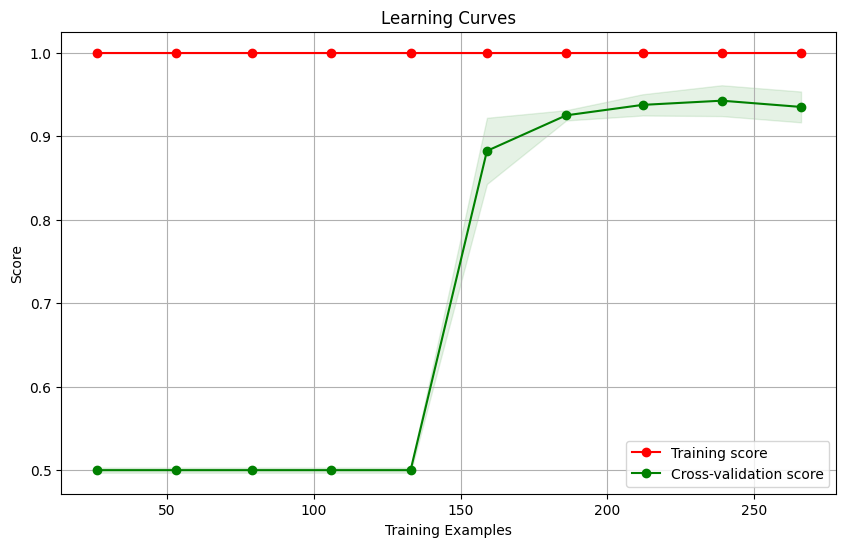

In [ ]:
##### YOUR CODE STARTS HERE #####

# Pass the appropriate parameters to the previously defined function plot_learning_curves()
plot_learning_curves(rf_model, train_images, train_labels)

##### YOUR CODE ENDS HERE #####

Does your model suffer from overfitting, underfitting, neither and why? Elaborate in depth and provide insight based on the bias and variance.

Answer: Elias: This model brought better results than the two before, regarding both the smaller gap on the graph, and the validation score and cross-validation.
To stay accurate, the small gap remaining reflects a certain degree of overfitting. End.

#### Comments

You describe a narrow, stable gap with both curves high, which reads as "neither" or only slight overfitting. That aligns with forests reducing variance (instability).

#### Hyperparameter tuning

Use the **GridSearchCV** module of the **sklearn** library to tune the hyperparameters of your `Random Forest` model on the TRAINING set. Focus on key parameters such as `n_estimators`, `max_depth`, `min_samples_split`, `min_samples_leaf`, and the split `criterion` (gini or entropy). Your tuning should be guided by the observations you made from the learning curve of the untuned model.  
Please note that when searching through many parameters, this might take time since it's going through every possible combination.

In [ ]:
##### YOUR CODE STARTS HERE #####

# Define your parameters
param_grid = {
    'n_estimators': [100, 200, 300],          # Number of trees in the forest (more trees = potentially better performance but slower)
    'max_depth': [10, 20, None],             # Maximum depth of each tree (None = grow until all leaves are pure)
    'min_samples_split': [2, 5, 10],     # Minimum samples required to split an internal node
    'min_samples_leaf': [1, 2, 4],      # Minimum samples required at a leaf node (prevents very small leaves/overfitting)
    'criterion': ['gini', 'entropy']              # Function to measure the quality of a split
}


# Initialize the grid search
grid_search = GridSearchCV(rf_model, param_grid, cv=3, scoring='accuracy', n_jobs=-1)

# Fit the model
grid_search.fit(train_images, train_labels)


##### YOUR CODE ENDS HERE #####

print("Best parameters:", grid_search.best_params_)
print("Best cross-validation score:", grid_search.best_score_)

##### YOUR CODE STARTS HERE #####

# Evaluate the best model on the validation set
# Get the best model
best_model = grid_search.best_estimator_

# Predict labels for the validation set
val_pred = best_model.predict(val_images)

# Report the validation accuracy of the trained model
val_accuracy = accuracy_score(val_labels, val_pred)

##### YOUR CODE ENDS HERE #####
print(f"Validation accuracy with best model: {val_accuracy:.4f}")
results.append((best_model, val_accuracy))

Best parameters: {'criterion': 'gini', 'max_depth': 20, 'min_samples_leaf': 1, 'min_samples_split': 5, 'n_estimators': 200}
Best cross-validation score: 0.9449743762391053
Validation accuracy with best model: 0.9700


Elias: Again tuning is a success.As in all 3 models before.End.

### Support Vector Machines

Train a linear Support Vector Machines model using the default hyperparameters and validate it on the validation set.

In [ ]:
##### YOUR CODE STARTS HERE #####
# for more info about the model
# refer to https://scikit-learn.org/stable/modules/generated/sklearn.svm.SVC.html

# initialize and train the Support Vector Machines model, use a linear kernel
svm_model = SVC(kernel='linear')

# train the model using training data
svm_model.fit(train_images, train_labels)

# report the number of support vectors
print("Number of support vectors:", svm_model.n_support_) # This returns an array with the number of support vectors for each class. To get the total count, we would sum the values in this array


# predict labels for the validation set
val_pred = svm_model.predict(val_images)

# report the validation accuracy of the trained model
val_accuracy = accuracy_score(val_labels, val_pred)
print(f"Validation accuracy: {val_accuracy:.4f}")

##### YOUR CODE ENDS HERE #####


Number of support vectors: [33 44]
Validation accuracy: 0.9500


Plot the learning curve of the trained model to examine bias and variance

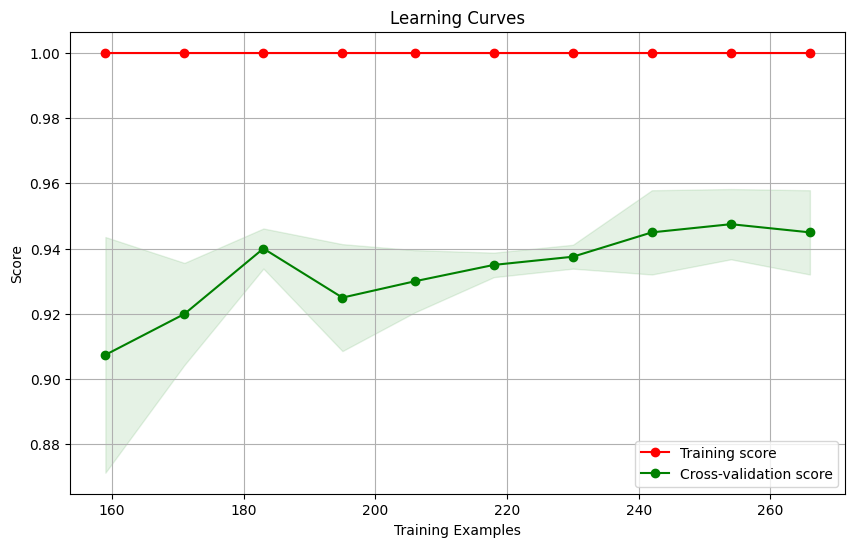

In [ ]:
##### YOUR CODE STARTS HERE #####

# pass the appropriate parameters to the previously defined function plot_learning_curves()
plot_learning_curves(svm_model, train_images, train_labels)

##### YOUR CODE ENDS HERE #####

Does your model suffer from overfitting, underfitting, neither and why? Elaborate in depth and provide insight based on the bias and variance.

Answer: Elias: High variance exists, easy to detect on graph. End.

#### Comments

The statement "High variance exists" isn't tied to curve features. A solid call needs concrete cues like "train high, validation lower, gap stays" for overfitting or "both low and close" for underfitting (too simple).

#### Hyperparameter tuning

Use the **GridSearchCV** module of the **sklearn** library to tune the hyperparameter of your `Support Vector Machines` model on the training set. You should try to tune as many hyperparameters as you can, such as the `regularization parameter C`, the `kernel`, the `degree of polynomial kernels,` and the `gamma parameter`. Your tuning should be guided by the observations you made from the learning curve of the untuned model. Again note that searching through many parameters will take some time.

In [ ]:
##### YOUR CODE STARTS HERE #####

# Define your parameters
param_grid = {
    'C': [0.1, 1, 10, 100],          # Regularization strength
    'kernel': ['linear', 'rbf', 'poly'],     # Kernel type
    'gamma': ['scale', 'auto', 0.1, 1],      # Kernel coefficient
    'degree': [2, 3, 4]      # Degree for polynomial kernel

}

# Initialize the grid search
grid_search = GridSearchCV(svm_model, param_grid, cv=3, scoring='accuracy', n_jobs=-1)

# Fit the model using the training data
grid_search.fit(train_images, train_labels)

##### YOUR CODE ENDS HERE #####

print("Best parameters:", grid_search.best_params_)
print("Best cross-validation score:", grid_search.best_score_)

##### YOUR CODE STARTS HERE #####
# Evaluate the best model on the validation set
# Get the best model
best_model = grid_search.best_estimator_

# Predict labels for the validation set
val_pred = best_model.predict(val_images)

# Report the validation accuracy of the trained model
val_accuracy = accuracy_score(val_labels, val_pred)

##### YOUR CODE ENDS HERE #####
print(f"Validation accuracy with best model: {val_accuracy:.4f}")
results.append((best_model, val_accuracy))

Best parameters: {'C': 1, 'degree': 2, 'gamma': 'scale', 'kernel': 'rbf'}
Best cross-validation score: 0.9649683911270714
Validation accuracy with best model: 0.9700


Elias: Very high score for SVM.End.

### Feed-forward Neural Network

We will be traininig a Feed-forward Neural Network consisting of three layers. The first hidden layer has 128 units and uses the ReLU activation function, the second hidden layer has 64 units and uses the ReLU activation function, and the output layer has 1 unit and uses sigmoid activation for binary classification.
We'll use the Adam optimizer to train the neural network, and then validate you will validate the model using the validation set.

In [ ]:
# function to create a dense model
def create_dense_model(input_shape):
    K.clear_session()
    model = Sequential([
        Input(shape=input_shape),       # Input layer
        Flatten(),                      # Flatten the input images
        Dense(128, activation='relu'),  # First hidden layer with 128 units and ReLU activation
        Dense(64, activation='relu'),   # Second hidden layer with 64 units and ReLU activation
        Dense(1, activation='sigmoid')  # Output layer with 1 unit and sigmoid activation for binary classification
    ])
    model.compile(optimizer='adam',
                  loss='binary_crossentropy',
                  metrics=['accuracy'])
    return model

# function to extract the dense model from the pipeline
def extract_model(pipeline):
    return pipeline.steps[-1][1]

# Create a pipeline for the dense model
dense_pipeline = Pipeline([
    ('flatten', FunctionTransformer(lambda x: x.reshape((x.shape[0], -1)))),
    ('dense', KerasClassifier(model=create_dense_model, input_shape=(10000,), epochs=10, batch_size=32))
])


model= extract_model(dense_pipeline)

##### YOUR CODE STARTS HERE #####

# train the model using training data
dense_pipeline.fit(train_images, train_labels)

# predict labels for the validation set
y_val_pred = dense_pipeline.predict(val_images)

# report the validation accuracy of the trained model
val_accuracy = accuracy_score(val_labels, y_val_pred)


##### YOUR CODE ENDS HERE #####
print(f"Validation Accuracy: {val_accuracy}")

Epoch 1/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 2s 22ms/step - accuracy: 0.6394 - loss: 0.9183
Epoch 2/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.8537 - loss: 0.3638
Epoch 3/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - accuracy: 0.9059 - loss: 0.2937
Epoch 4/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - accuracy: 0.9148 - loss: 0.2029
Epoch 5/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - accuracy: 0.8778 - loss: 0.2823
Epoch 6/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.9091 - loss: 0.2160
Epoch 7/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.9486 - loss: 0.1068
Epoch 8/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 0.9345 - loss: 0.1574
Epoch 9/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.9226 - loss: 0.2115
Epoch 10/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - accuracy: 0.9468 - loss: 0.1042
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step
Validation Accuracy: 0.95


We will use a different plotting function for the NN. Feel free to read through it to understand a sense of what's happening under the hood of the `learning_curve` method.

In [ ]:
def plot_keras_learning_curves(x_train, y_train,
                               epochs=10, batch_size=32,
                               train_sizes=np.linspace(0.1, 1.0, 5),
                               validation_split=0.2):
    train_scores = []
    val_scores = []
    num_train = x_train.shape[0]
    train_examples = []

    # Shuffle the dataset once to ensure randomness in subsets
    indices = np.arange(num_train)
    np.random.shuffle(indices)
    x_train = x_train[indices]
    y_train = y_train[indices]

    # Loop through different fractions of the training data
    for frac in train_sizes:
        subset_size = int(frac * num_train)
        x_subset = x_train[:subset_size]
        y_subset = y_train[:subset_size]

        # Create a fresh model for each subset to get an unbiased measure
        model = create_dense_model(input_shape=(x_train.shape[1],))

        # Train the model and capture history
        history = model.fit(
            x_subset, y_subset,
            validation_split=validation_split,
            epochs=epochs,
            batch_size=batch_size,
            verbose=0
        )

        # Store final training and validation accuracy for this subset
        train_scores.append(history.history['accuracy'][-1])
        val_scores.append(history.history['val_accuracy'][-1])
        train_examples.append(subset_size)

    # Plot
    plt.figure(figsize=(10, 6))
    plt.plot(train_examples, train_scores, 'o-', color="r", label="Training Accuracy")
    plt.plot(train_examples, val_scores, 'o-', color="g", label="Validation Accuracy")
    plt.xlabel("Number of Training Examples")
    plt.ylabel("Accuracy")
    plt.title("Keras Learning Curves")
    plt.legend(loc="best")
    plt.grid(True)
    plt.show()


Plot the learning curve of the model to observe how its training and validation accuracy change with increasing training data. This helps analyze the model’s bias and variance behavior and identify potential overfitting or underfitting trends.

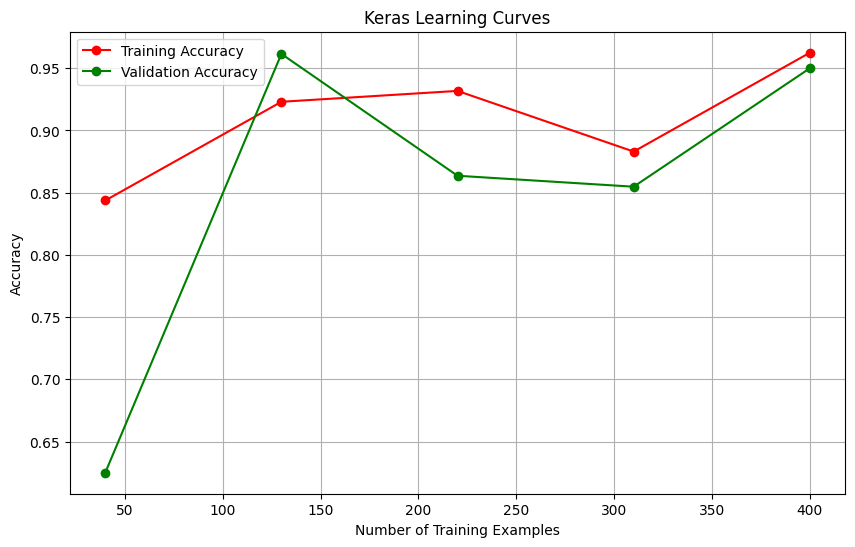

In [ ]:
##### YOUR CODE STARTS HERE #####

# Pass the appropriate parameters to the previously defined function, no need to edit the epochs and batch_size
plot_keras_learning_curves(train_images, train_labels)
##### YOUR CODE ENDS HERE #####
results.append((model, val_accuracy))

Does your model suffer from overfitting, underfitting, neither and why? Elaborate in depth and provide insight based on the bias and variance.

Answer: Elias: By far this is a better model more suited to our data type which is images.
(The 2nd model in order is Random Forest)
Here we neither have over or underfitting, the gap is very narrow, the points of the curves are heading high (no bias).
It learned well on the training data and generalyzing well on unseen data ( the validation images).End.


#### Comments

You state "neither" with a narrow gap and high levels, which can indicate balanced behavior. The evidence mentions the small gap and strong validation, but it would be clearer if you referenced what happens at larger sizes (do the lines stay close or drift).

## Part 4: Testing

Select the best tuned model from all the five models you have trained in part 4, and then test it on the test data

In [ ]:
##### YOUR CODE STARTS HERE #####

# Find the best model based on the highest score
best = max(results, key=lambda x: x[1])

# Find the best model
final_best_model = best[0]

# Predict labels for the test set
print("Best model:", final_best_model)

# Make predictions on the test set using the best model
test_pred = final_best_model.predict(test_images)

# Calculate the test accuracy
accuracy = accuracy_score(test_labels, test_pred)

##### YOUR CODE ENDS HERE #####
print("Test Accuracy:", accuracy)

Best model: KerasClassifier(
	model=<function create_dense_model at 0x7a3c0b40ede0>
	build_fn=None
	warm_start=False
	random_state=None
	optimizer=rmsprop
	loss=None
	metrics=None
	batch_size=32
	validation_batch_size=None
	verbose=1
	callbacks=None
	validation_split=0.0
	shuffle=True
	run_eagerly=False
	epochs=10
	input_shape=(10000,)
	class_weight=None
)
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step
Test Accuracy: 0.94


Elias: The best model chosen is feed-fwd NN, the test accuracy is high (very good outcome). Model reliable and robust.

Overall I am understanding the phases to some good extent.
Writing the code is very difficult, no i am not practicing enough, yes I have Kaggle and it is cool, I explored it.
Yet I am not worried it can come with time; my priority now is to digest and assimilate the concepts, deeply understand, I can practice coding anytime later.

My big challenge in this assignment (same as previous) is to decipher the meaning of the results, scores, curve significance, it is still a struggle and I feel lost in front of the numbers.

Thanks.